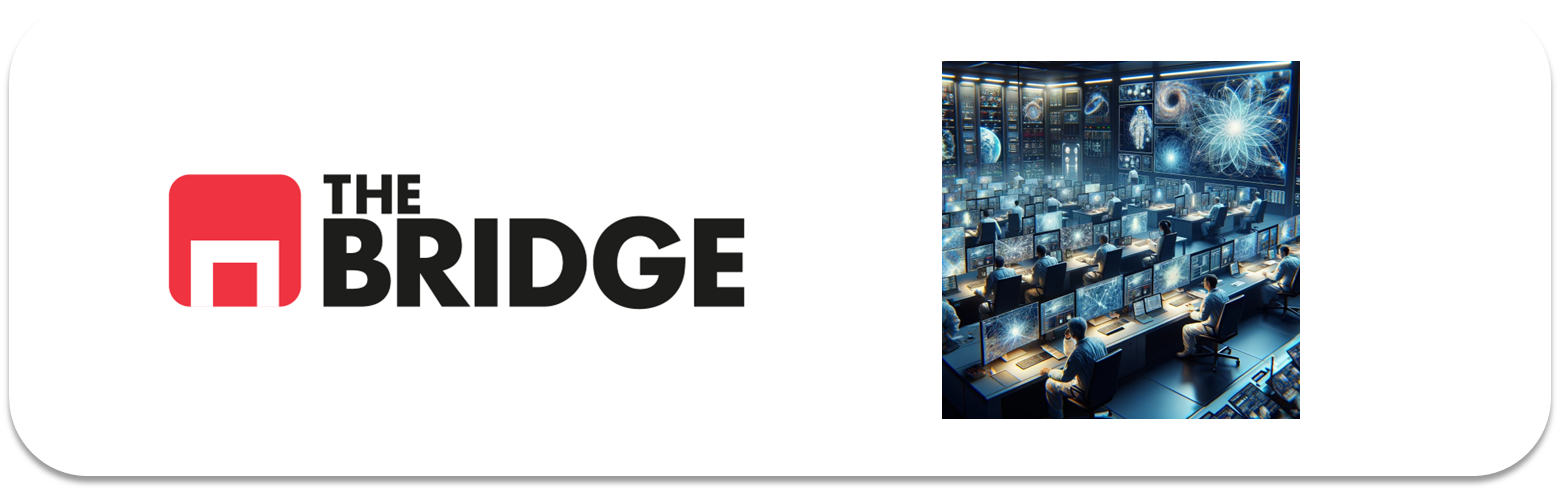

## PRÁCTICA OBLIGATORIA: **Transfer Learning y Fine-tuning con CNN**

* La práctica obligatoria de esta unidad consiste en repetir el ejercicio de construcción de un modelo de clasificación de paisajes de la unidad anterior, pero usando un modelo preentrenado. Puedes trabajar en local o en Colab: las imágenes se descargan desde Kaggle con `kagglehub` (no hace falta tener cuenta). Si no tienes GPU, te recomendamos Colab con un entorno de GPU.
* Recuerda que debes subirla a tu repositorio personal antes de la sesión en vivo para que puntúe adecuadamente.
* Recuerda también que no es necesario que esté perfecta, solo es necesario que se vea el esfuerzo.
* Esta práctica se resolverá en la sesión en vivo correspondiente y la solución se publicará en el repo del curso.

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/DS-TB-FundacionUniversia/2026-09-DS-Universia/blob/main/05_Deep_Learning/03_Transfer_Learning/soluciones/P01_Practica_Transfer_Learning_SOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import os
from time import time

import cv2 # opencv
import kagglehub
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from keras.applications.inception_v3 import InceptionV3, preprocess_input
from skimage.io import imread
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.utils import shuffle

pd.options.mode.copy_on_write = True # CoW por defecto a partir de pandas 3.0.0
keras.utils.set_random_seed(42) # Para que los entrenamientos sean (casi) reproducibles

### Objetivo del ejercicio

Comparar una red convolucional hecha ad-hoc frente a un modelo preentrenado, primero con transfer learning (extracción de características) y después con fine-tuning. Para ello emplea el dataset de paisajes ([Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)) del conjunto de ejercicios de la unidad anterior.

### Se pide

1. Preparar los datos del modelo y las funciones de visualización. Copia para ello todo lo que necesites de las soluciones del ejercicio de clasificación de paisajes de la unidad anterior (las imágenes se descargan con `kagglehub.dataset_download("puneet6060/intel-image-classification")`).

2. Escoger uno de estos modelos preentrenados de [Keras Applications](https://keras.io/api/applications/): MobileNetV2, EfficientNetB0, InceptionV3 o ResNet50V2 (se aconseja MobileNetV2 si no tienes un ordenador muy potente). Consulta en la documentación del modelo escogido su tamaño mínimo de entrada y su `preprocess_input`, y úsalos.

3. Hacer un transfer learning (fase 1: base congelada) con una cabeza de como mucho 2 capas densas ocultas y una de salida. Mostrar la evaluación contra test, el report de clasificación y la matriz de confusión.

4. Hacer un fine-tuning (fase 2) partiendo del modelo del punto anterior: descongela las últimas capas de la base y vuelve a entrenar con un learning rate muy bajo (del orden de 1e-5). Mostrar la evaluación contra test, el report de clasificación y la matriz de confusión.

5. Comparar los resultados con los obtenidos con la red convolucional del ejercicio de la unidad anterior (en torno a un 77 % de accuracy en test).

EXTRA:
- Repetir el transfer learning empleando aumentado de imágenes.

### #1: Funciones y preparación de datos (código adaptado de la solución del ejercicio de la unidad anterior)

*Descargamos el dataset con `kagglehub`. Devuelve la ruta local donde lo ha dejado (una caché en tu carpeta de usuario, o en `/root/.cache` en Colab), así que no ocupa sitio en el repositorio.*

In [2]:
PATH_DATA = kagglehub.dataset_download("puneet6060/intel-image-classification")
print(os.listdir(PATH_DATA))

TRAIN_PATH = os.path.join(PATH_DATA, "seg_train", "seg_train")
TEST_PATH = os.path.join(PATH_DATA, "seg_test", "seg_test")
print(sorted(os.listdir(TRAIN_PATH)))

['seg_pred', 'seg_test', 'seg_train']
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


(150, 150, 3)


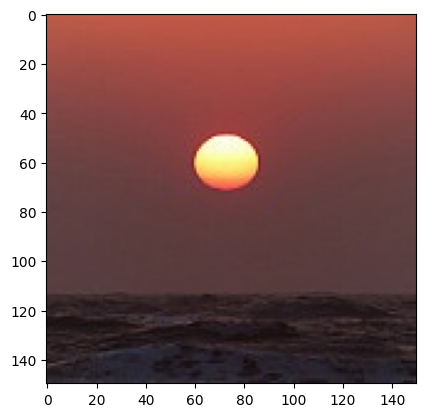

In [3]:
imagen = imread(os.path.join(TRAIN_PATH, "sea", "11321.jpg"))
print(imagen.shape)
plt.imshow(imagen)
plt.show()

*Las imágenes son de 150x150. Introducimos un parámetro de control de la resolución, según las dimensiones de entrada de nuestra red, que podemos tocar sin cambiar nada del resto del código. Vamos a usar InceptionV3, que según su documentación no admite entradas menores de 75x75, así que usaremos ese tamaño (cuanto mayor, mejor transferencia pero más lento).*

In [4]:
IMG_WIDTH = IMG_HEIGHT = 75

def read_data(directorio, reshape_dim = (IMG_WIDTH, IMG_HEIGHT)):
    X = []
    y = []
    for folder in sorted(os.listdir(directorio)):
        for file in sorted(os.listdir(os.path.join(directorio, folder))):
            image = imread(os.path.join(directorio, folder, file))
            X.append(cv2.resize(image, reshape_dim)) # Redimensionamos las imágenes a 75x75
            y.append(folder)
    return np.array(X), np.array(y)

def show_images_batch(paisajes, names = [], n_cols = 5, size_scale = 2):
    n_rows = ((len(paisajes) - 1) // n_cols + 1)
    plt.figure(figsize=(n_cols * size_scale, n_rows * 1.1 * size_scale))
    for index, paisaje in enumerate(paisajes):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(paisaje)
        plt.axis("off")
        if len(names):
            plt.title(names[index])
    plt.show()

In [5]:
X_train, y_train = read_data(TRAIN_PATH)
X_test, y_test = read_data(TEST_PATH)
print(X_train.shape, X_test.shape, X_train.dtype)

(14034, 75, 75, 3) (3000, 75, 75, 3) uint8


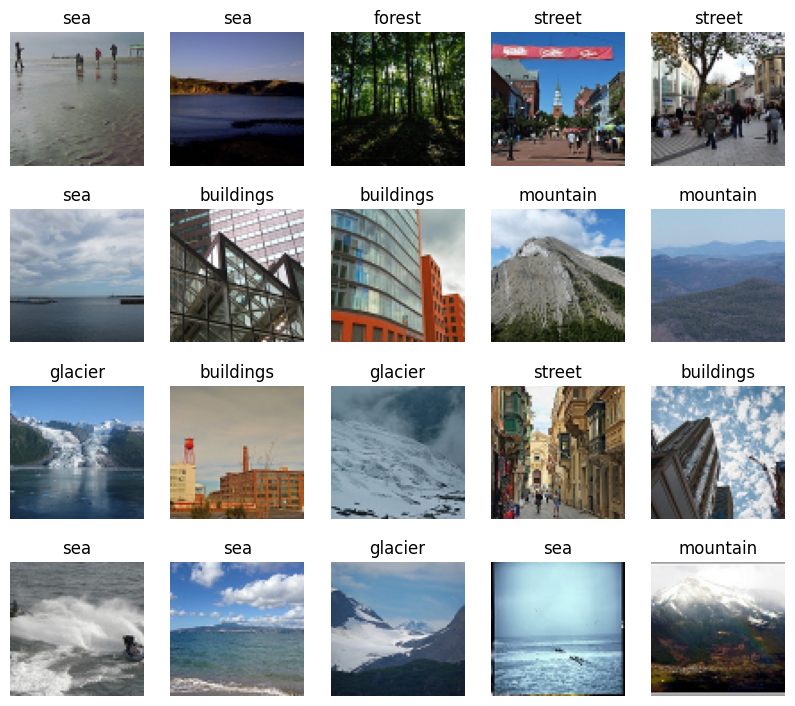

In [6]:
indices = np.random.default_rng(42).choice(len(X_train), 20, replace=False)
show_images_batch(X_train[indices], names = y_train[indices], n_cols = 5)

In [7]:
pd.Series(y_train).value_counts(normalize=True)

mountain     0.178994
glacier      0.171298
street       0.169731
sea          0.162035
forest       0.161821
buildings    0.156121
Name: proportion, dtype: float64

*Seis clases bastante equilibradas, así que la accuracy es una buena métrica. Convertimos las etiquetas a números (en orden alfabético, el mismo que usaría Keras si leyéramos las imágenes desde directorios) y barajamos el train: `validation_split` no baraja y nuestros datos están ordenados por clase.*

In [8]:
clases = np.unique(y_train)
mapa = {clase: indice for indice, clase in enumerate(clases)}
inverse_map = {indice: clase for clase, indice in mapa.items()}
print(mapa)

y_train_num = np.array([mapa[y] for y in y_train])
y_test_num = np.array([mapa[y] for y in y_test])

X_train_s, y_train_s = shuffle(X_train, y_train_num, random_state=42)

{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


*No escalamos los arrays: InceptionV3 espera los píxeles entre -1 y 1, y para eso usaremos su `preprocess_input` dentro del propio modelo. Así el modelo recibe siempre imágenes en [0, 255], tanto en train como en test, y no hay forma de equivocarse de preprocesado (y los arrays en `uint8` ocupan 4 veces menos memoria).*

### #2: Selección del modelo

*Escogemos [Inception V3](https://arxiv.org/abs/1512.00567): buena precisión en ImageNet (77,9 % top-1) con un tamaño moderado (24 millones de parámetros). Veamos qué devuelve su base convolucional a 75x75:*

In [9]:
temp_model = InceptionV3(include_top=False, weights="imagenet", input_shape=(IMG_WIDTH, IMG_HEIGHT, 3))
print(temp_model.output.shape, len(temp_model.layers), "capas")
del temp_model

(None, 1, 1, 2048) 311 capas


*A esta resolución la base devuelve un mapa de 1x1x2048: un vector de 2048 características por imagen.*

### #3: Transfer Learning (fase 1: base congelada)

*Construimos el modelo con una función que crea **una base nueva en cada llamada** (así ningún modelo comparte pesos con otro) y que nos servirá también para el EXTRA:*

* *`preprocess_input` de InceptionV3 dentro del modelo.*
* *Base congelada y llamada con `training=False`, para que BatchNormalization trabaje siempre en modo inferencia (también en el fine-tuning).*
* *`GlobalAveragePooling2D` + una capa oculta de 256 unidades con Dropout + salida softmax de 6 unidades. El número de unidades de la capa oculta es un hiperparámetro más, no tiene por qué coincidir con el número de características de la base.*

In [10]:
def prepare_model(aumentado = False):
    base_model = InceptionV3(include_top=False, weights="imagenet", input_shape=(IMG_WIDTH, IMG_HEIGHT, 3))
    base_model.trainable = False

    inputs = keras.Input(shape=(IMG_WIDTH, IMG_HEIGHT, 3))
    x = inputs
    if aumentado: # Solo actúa durante el entrenamiento
        x = keras.layers.RandomFlip("horizontal")(x)
        x = keras.layers.RandomRotation(0.05)(x)
        x = keras.layers.RandomZoom(0.1)(x)
    x = preprocess_input(x) # [0, 255] -> [-1, 1]
    x = base_model(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(256, activation="relu")(x)
    x = keras.layers.Dropout(0.3)(x)
    outputs = keras.layers.Dense(len(clases), activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy", # y es un entero por clase
                  metrics=["accuracy"])
    return model, base_model

model, base_model = prepare_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 1, 1, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,328,870 (85.18 MB)

 Trainable params: 526,086 (2.01 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

*Solo son entrenables los parámetros de la cabeza (algo más de medio millón); los casi 22 millones de la base están congelados. Con más de 11000 imágenes de entrenamiento podemos permitirnos batches de 128 (unos 88 steps por época) y un EarlyStopping con paciencia 5:*

In [11]:
batch_size = 128
early_stopping = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

t_zero = time()
history = model.fit(X_train_s, y_train_s,
                    batch_size=batch_size,
                    validation_split=0.2,
                    epochs=30,
                    callbacks=[early_stopping])
print(f"Tiempo de entrenamiento: {time() - t_zero:.0f} s")

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 66s 548ms/step - accuracy: 0.5898 - loss: 1.0944 - val_accuracy: 0.7706 - val_loss: 0.6193
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 41s 472ms/step - accuracy: 0.7987 - loss: 0.5474 - val_accuracy: 0.7805 - val_loss: 0.5886
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 37s 426ms/step - accuracy: 0.8336 - loss: 0.4465 - val_accuracy: 0.7895 - val_loss: 0.5784
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 41s 471ms/step - accuracy: 0.8676 - loss: 0.3661 - val_accuracy: 0.7866 - val_loss: 0.5987
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 39s 448ms/step - accuracy: 0.8977 - loss: 0.2992 - val_accuracy: 0.7795 - val_loss: 0.6334
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 42s 474ms/step - accuracy: 0.9077 - loss: 0.2608 - val_accuracy: 0.7805 - val_loss: 0.6345
Epoch 7/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 34s 389ms/step - accuracy: 0.9276 - loss: 0.2122 - val_accuracy: 0.7763 - val_loss: 0.6959
Epoch 8/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 22s 255ms/step - accuracy: 0.9413 - loss: 0.1814 - val_accu

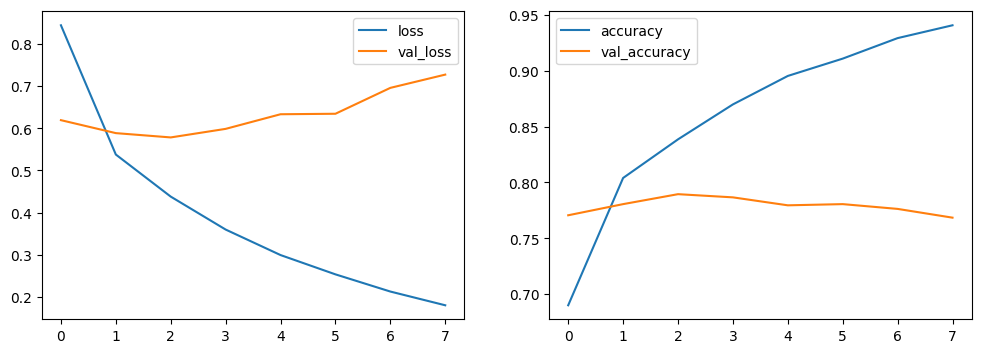

In [12]:
evol = pd.DataFrame(history.history)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
evol[["loss", "val_loss"]].plot(ax=axs[0])
evol[["accuracy", "val_accuracy"]].plot(ax=axs[1])
plt.show()

*La validación se estanca enseguida en torno al 79 % (la mejor `val_loss` llega en la época 3) mientras el train sigue subiendo hasta el 94 %: en cuanto la cabeza ha sacado todo lo que dan las características congeladas, empieza a sobreajustar, y el EarlyStopping se queda con la época 3. Las características de ImageNet no separan estos paisajes tan bien como separaban perros y gatos: la tarea se parece menos a la de origen (escenas frente a objetos) y además trabajamos a solo 75x75 píxeles.*

In [13]:
results_tl = model.evaluate(X_test, y_test_num)
print("test loss, test acc:", results_tl)

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.7929 - loss: 0.5281
test loss, test acc: [0.5716538429260254, 0.7903333306312561]


94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms/step
              precision    recall  f1-score   support

   buildings       0.84      0.78      0.81       437
      forest       0.91      0.96      0.93       474
     glacier       0.74      0.66      0.70       553
    mountain       0.68      0.76      0.71       525
         sea       0.80      0.75      0.77       510
      street       0.80      0.86      0.83       501

    accuracy                           0.79      3000
   macro avg       0.80      0.79      0.79      3000
weighted avg       0.79      0.79      0.79      3000



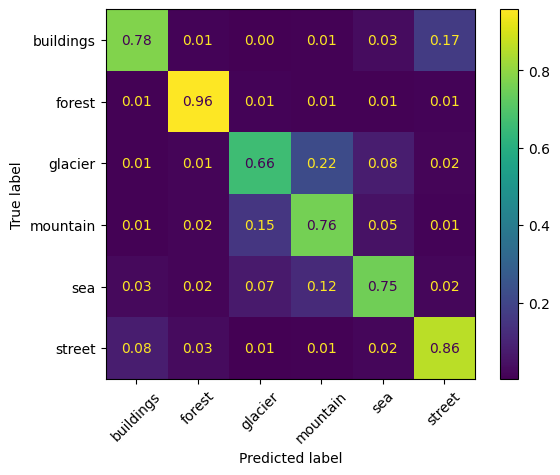

In [14]:
def informe(model):
    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_test_labels = [inverse_map[y] for y in y_test_num]
    y_pred_labels = [inverse_map[y] for y in y_pred]
    print(classification_report(y_test_labels, y_pred_labels))
    ConfusionMatrixDisplay.from_predictions(y_test_labels, y_pred_labels, normalize="true", values_format=".2f", xticks_rotation=45)
    plt.show()

informe(model)

*Un 79 % en test, en línea con la validación, pero solo 2 puntos más que la CNN ad-hoc de la unidad anterior (76,9 %): no es mucha ganancia para tanto armatoste. Por clases el patrón se parece al de entonces: los bosques (96 % de recall) y las calles van muy bien, mientras que glaciares, montañas y mar se confunden entre sí (un 22 % de los glaciares se predicen como montañas) y los edificios se confunden con calles (17 %). Son confusiones razonables: a 75x75 un glaciar y una montaña nevada se parecen mucho.*

### #4: Fine-tuning (fase 2)

*Partimos del modelo que acabamos de entrenar (la cabeza ya ha convergido) y descongelamos los dos últimos bloques "inception" de la base (las capas posteriores a `mixed8`, como en el ejemplo de la documentación de Keras), dejando congeladas las BatchNormalization. Recompilamos con un learning rate muy bajo para reajustar ligeramente los pesos sin destrozar lo aprendido en ImageNet (olvido catastrófico).*

*Fíjate en que no descongelamos toda la red desde el principio: con la cabeza recién inicializada (pesos aleatorios) sus gradientes iniciales, enormes, se propagarían hacia la base y estropearían los pesos preentrenados.*

In [15]:
base_model.trainable = True
indice_mixed8 = [layer.name for layer in base_model.layers].index("mixed8")
for i, layer in enumerate(base_model.layers):
    if i <= indice_mixed8 or isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print("Capas entrenables de la base:", sum(layer.trainable for layer in base_model.layers), "de", len(base_model.layers))

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Capas entrenables de la base: 44 de 311


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 1, 1, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,328,870 (85.18 MB)

 Trainable params: 11,634,438 (44.38 MB)

 Non-trainable params: 10,694,432 (40.80 MB)

In [16]:
t_zero = time()
history_ft = model.fit(X_train_s, y_train_s,
                       batch_size=batch_size,
                       validation_split=0.2, # La misma validación que en la fase 1
                       epochs=15,
                       callbacks=[early_stopping])
print(f"Tiempo de entrenamiento: {time() - t_zero:.0f} s")

Epoch 1/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 57s 586ms/step - accuracy: 0.8733 - loss: 0.3496 - val_accuracy: 0.8147 - val_loss: 0.5263
Epoch 2/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 53s 600ms/step - accuracy: 0.9141 - loss: 0.2523 - val_accuracy: 0.8272 - val_loss: 0.5113
Epoch 3/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 53s 601ms/step - accuracy: 0.9358 - loss: 0.2035 - val_accuracy: 0.8265 - val_loss: 0.5125
Epoch 4/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 50s 571ms/step - accuracy: 0.9489 - loss: 0.1657 - val_accuracy: 0.8290 - val_loss: 0.5179
Epoch 5/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 52s 588ms/step - accuracy: 0.9598 - loss: 0.1362 - val_accuracy: 0.8322 - val_loss: 0.5193
Epoch 6/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 77s 527ms/step - accuracy: 0.9720 - loss: 0.1068 - val_accuracy: 0.8301 - val_loss: 0.5308
Epoch 7/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 41s 473ms/step - accuracy: 0.9791 - loss: 0.0878 - val_accuracy: 0.8329 - val_loss: 0.5361
Tiempo de entrenamiento: 424 s


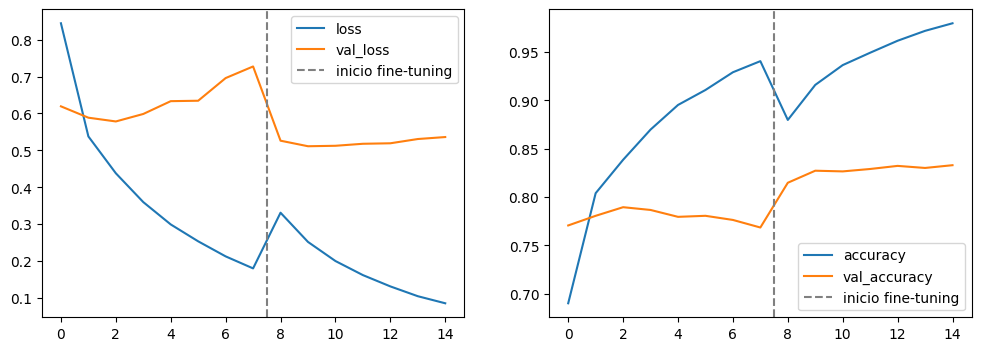

Fase 1 - mejor val_loss: 0.5784, val_accuracy en esa época: 0.7895
Fase 2 - mejor val_loss: 0.5113, val_accuracy en esa época: 0.8272


In [17]:
evol_ft = pd.concat([evol, pd.DataFrame(history_ft.history)], ignore_index=True)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axs, ["loss", "accuracy"]):
    evol_ft[[metrica, "val_" + metrica]].plot(ax=ax)
    ax.axvline(len(evol) - 0.5, color="grey", linestyle="--", label="inicio fine-tuning")
    ax.legend()
plt.show()

evol_fase2 = pd.DataFrame(history_ft.history)
print(f"Fase 1 - mejor val_loss: {evol['val_loss'].min():.4f}, val_accuracy en esa época: {evol['val_accuracy'][evol['val_loss'].idxmin()]:.4f}")
print(f"Fase 2 - mejor val_loss: {evol_fase2['val_loss'].min():.4f}, val_accuracy en esa época: {evol_fase2['val_accuracy'][evol_fase2['val_loss'].idxmin()]:.4f}")

*Al descongelar los dos últimos bloques la pérdida de validación baja de 0,578 a 0,511 ya en la segunda época, y la accuracy de validación pasa del 79 % al 83 %. Después la `val_loss` deja de mejorar (aunque la accuracy aún sube un poco) y el train se dispara hacia el 98 %, señal de que empezamos a sobreajustar, así que el EarlyStopping restaura la época 2.*

In [18]:
results_ft = model.evaluate(X_test, y_test_num)
print("test loss, test acc:", results_ft)

94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.8154 - loss: 0.4714
test loss, test acc: [0.5185044407844543, 0.8146666884422302]


94/94 ━━━━━━━━━━━━━━━━━━━━ 21s 167ms/step
              precision    recall  f1-score   support

   buildings       0.83      0.83      0.83       437
      forest       0.94      0.95      0.95       474
     glacier       0.79      0.67      0.73       553
    mountain       0.72      0.75      0.73       525
         sea       0.81      0.83      0.82       510
      street       0.81      0.88      0.85       501

    accuracy                           0.81      3000
   macro avg       0.82      0.82      0.82      3000
weighted avg       0.81      0.81      0.81      3000



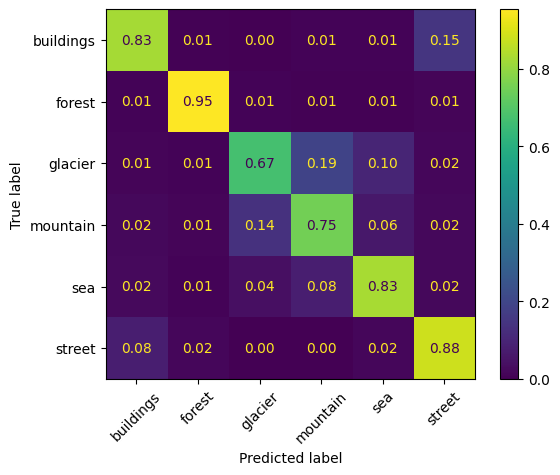

In [19]:
informe(model)

*El fine-tuning sube la accuracy en test al 81,5 % (2,4 puntos más que la fase 1). Mejora sobre todo el mar (del 75 % al 83 % de recall) y los edificios (del 78 % al 83 %), mientras que la confusión entre glaciares y montañas sigue siendo el gran problema.*

### #5: Comparación con la CNN de la unidad anterior

In [20]:
pd.DataFrame({"modelo": ["CNN ad-hoc (unidad anterior)", "InceptionV3 transfer learning", "InceptionV3 fine-tuning"],
              "accuracy test": [0.769, results_tl[1], results_ft[1]]}).round(3)

,modelo,accuracy test
0,CNN ad-hoc (unidad anterior),0.769
1,InceptionV3 transfer learning,0.790
2,InceptionV3 fine-tuning,0.815


*El modelo preentrenado mejora a la CNN hecha a mano, pero no de forma espectacular: unos 2 puntos con extracción de características y unos 4,5 con fine-tuning. ¿Por qué tan poco, cuando con perros y gatos pasábamos de un 72-78 % a más de un 96 %?*

* *El dominio se parece menos al de ImageNet (escenas frente a objetos) y la resolución de 75x75 está muy lejos de los 299x299 con los que se preentrenó InceptionV3.*
* *Tenemos bastantes datos (14000 imágenes), así que la CNN ad-hoc ya partía de un nivel razonable.*

*Siguiendo la matriz "datos frente a similitud" de la presentación, con muchos datos y un dominio distinto lo indicado es un fine-tuning más profundo: descongelar más bloques (o toda la base), siempre después de la fase 1 y con learning rate bajo, y subir la resolución (las imágenes originales son de 150x150). Te lo dejamos como mejora: es bastante más costoso de entrenar y conviene hacerlo con GPU.*

### EXTRA: transfer learning con aumentado de imágenes

*Repetimos la fase 1 añadiendo al principio del modelo capas de aumentado de Keras (`RandomFlip`, `RandomRotation`, `RandomZoom`), que solo actúan durante el entrenamiento. Es la forma recomendada en Keras 3 (el `ImageDataGenerator` que vimos en la unidad anterior es *legacy*) y, al trabajar sobre los arrays que ya tenemos, nos ahorra volver a leer las imágenes de disco. Además, el modelo sigue recibiendo píxeles en [0, 255], así que no hay riesgo de aplicar un preprocesado distinto en train y en test.*

*Usamos exactamente la misma validación que antes para poder comparar.*

In [21]:
model_aug, _ = prepare_model(aumentado=True)

t_zero = time()
history_aug = model_aug.fit(X_train_s, y_train_s,
                            batch_size=batch_size,
                            validation_split=0.2,
                            epochs=30,
                            callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
print(f"Tiempo de entrenamiento: {time() - t_zero:.0f} s")

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 59s 604ms/step - accuracy: 0.5619 - loss: 1.1909 - val_accuracy: 0.7631 - val_loss: 0.6656
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 47s 533ms/step - accuracy: 0.7454 - loss: 0.6717 - val_accuracy: 0.7809 - val_loss: 0.6007
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 42s 474ms/step - accuracy: 0.7684 - loss: 0.6060 - val_accuracy: 0.7855 - val_loss: 0.5828
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 47s 538ms/step - accuracy: 0.7838 - loss: 0.5800 - val_accuracy: 0.7859 - val_loss: 0.5725
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 47s 531ms/step - accuracy: 0.7951 - loss: 0.5468 - val_accuracy: 0.7870 - val_loss: 0.5724
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 47s 534ms/step - accuracy: 0.7949 - loss: 0.5368 - val_accuracy: 0.7852 - val_loss: 0.5626
Epoch 7/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 47s 535ms/step - accuracy: 0.8064 - loss: 0.5130 - val_accuracy: 0.7944 - val_loss: 0.5556
Epoch 8/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 82s 535ms/step - accuracy: 0.8178 - loss: 0.4840 - val_accu

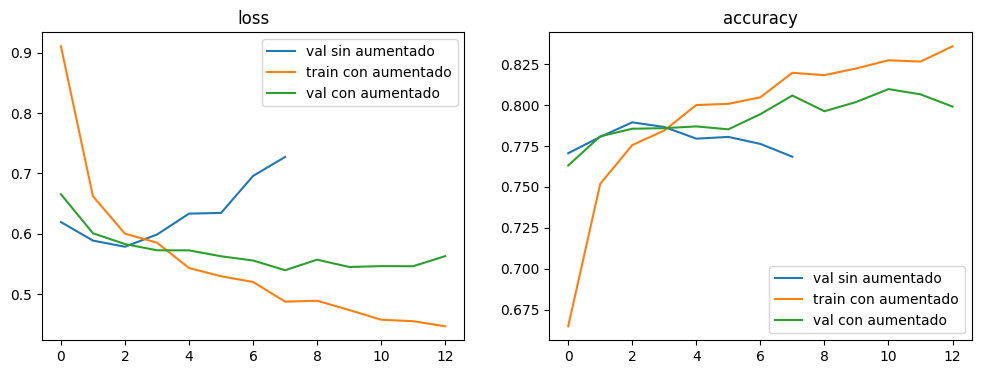

Sin aumentado - mejor val_loss: 0.5784, val_accuracy en esa época: 0.7895
Con aumentado - mejor val_loss: 0.5395, val_accuracy en esa época: 0.8058


In [22]:
evol_aug = pd.DataFrame(history_aug.history)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axs, ["loss", "accuracy"]):
    evol[["val_" + metrica]].rename(columns={"val_" + metrica: "val sin aumentado"}).plot(ax=ax)
    evol_aug[[metrica, "val_" + metrica]].rename(columns={metrica: "train con aumentado", "val_" + metrica: "val con aumentado"}).plot(ax=ax)
    ax.set_title(metrica)
plt.show()
print(f"Sin aumentado - mejor val_loss: {evol['val_loss'].min():.4f}, val_accuracy en esa época: {evol['val_accuracy'][evol['val_loss'].idxmin()]:.4f}")
print(f"Con aumentado - mejor val_loss: {evol_aug['val_loss'].min():.4f}, val_accuracy en esa época: {evol_aug['val_accuracy'][evol_aug['val_loss'].idxmin()]:.4f}")

*Con aumentado el modelo sobreajusta mucho menos: train y validación van de la mano y el entrenamiento aguanta más épocas antes de que la validación se estanque. La mejor `val_loss` baja de 0,578 a 0,540 y la accuracy de validación en esa época sube del 79 % al 80,6 %. Cada época es algo más lenta, porque las transformaciones se aplican en cada paso.*

94/94 ━━━━━━━━━━━━━━━━━━━━ 14s 146ms/step - accuracy: 0.7965 - loss: 0.4934
test loss, test acc: [0.5504328608512878, 0.7879999876022339]
94/94 ━━━━━━━━━━━━━━━━━━━━ 24s 201ms/step
              precision    recall  f1-score   support

   buildings       0.82      0.78      0.80       437
      forest       0.92      0.94      0.93       474
     glacier       0.73      0.72      0.72       553
    mountain       0.72      0.69      0.70       525
         sea       0.75      0.79      0.77       510
      street       0.80      0.82      0.81       501

    accuracy                           0.79      3000
   macro avg       0.79      0.79      0.79      3000
weighted avg       0.79      0.79      0.79      3000



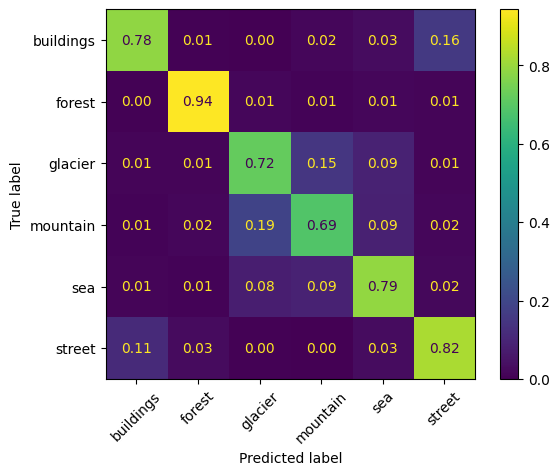

In [23]:
results_aug = model_aug.evaluate(X_test, y_test_num)
print("test loss, test acc:", results_aug)
informe(model_aug)

*En test, sin embargo, el modelo con aumentado se queda en un 78,8 %, prácticamente igual que sin aumentado (79,0 %). Con 3000 imágenes de test, una diferencia de 0,2 puntos está muy por debajo del margen de error (en torno a ±1,5 puntos), así que no podemos decir que uno sea mejor que otro. El aumentado reduce el sobreajuste de la cabeza, pero con la base congelada el límite lo ponen las características de ImageNet: para ir más allá hay que hacer fine-tuning (y nada impide combinar las dos cosas).*